In [1]:
# Cell 1: Setup, Imports, and Data Loading

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, recall_score, precision_score
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# --- DATA LOADING AND CLEANING ---
file_name = "[Dataset] carclaims.csv"
df = pd.read_csv(file_name)

# Clean column names by stripping whitespace
df.columns = df.columns.str.strip()

# Convert the target variable to numeric (0 = No, 1 = Yes)
df['FraudFound'] = df['FraudFound'].apply(lambda x: 1 if x.strip() == 'Yes' else 0)

print("--- Data Loading Complete. First 5 Rows: ---")
print(df.head().to_markdown())
print(f"\nTotal Records: {len(df)}")

--- Data Loading Complete. First 5 Rows: ---
|    | Month   |   WeekOfMonth | DayOfWeek   | Make   | AccidentArea   | DayOfWeekClaimed   | MonthClaimed   |   WeekOfMonthClaimed | Sex    | MaritalStatus   |   Age | Fault         | PolicyType        | VehicleCategory   | VehiclePrice     |   PolicyNumber |   RepNumber |   Deductible |   DriverRating | Days:Policy-Accident   | Days:Policy-Claim   | PastNumberOfClaims   | AgeOfVehicle   | AgeOfPolicyHolder   | PoliceReportFiled   | WitnessPresent   | AgentType   | NumberOfSuppliments   | AddressChange-Claim   | NumberOfCars   |   Year | BasePolicy   |   FraudFound |
|---:|:--------|--------------:|:------------|:-------|:---------------|:-------------------|:---------------|---------------------:|:-------|:----------------|------:|:--------------|:------------------|:------------------|:-----------------|---------------:|------------:|-------------:|---------------:|:-----------------------|:--------------------|:---------------------|:---


--- 2.1 Fraud Proportion ---
Genuine Claims (0): 14497 (94.01%)
Fraud Claims (1): 923 (5.99%)
Conclusion: Severe class imbalance (94:6) exists.


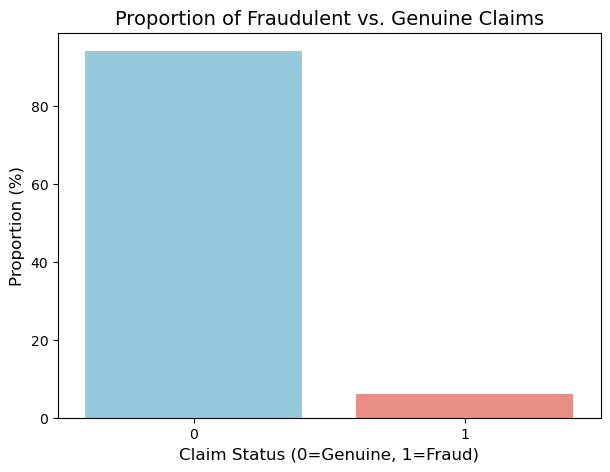

In [2]:
# Cell 2: RQ1 - Fraud Proportion (Class Imbalance)

print("\n--- 2.1 Fraud Proportion ---")
fraud_counts = df['FraudFound'].value_counts()
fraud_proportions = df['FraudFound'].value_counts(normalize=True) * 100

print(f"Genuine Claims (0): {fraud_counts[0]} ({fraud_proportions[0]:.2f}%)")
print(f"Fraud Claims (1): {fraud_counts[1]} ({fraud_proportions[1]:.2f}%)")
print("Conclusion: Severe class imbalance (94:6) exists.")

# Plotting the Fraud Proportion
plt.figure(figsize=(7, 5))
sns.barplot(x=fraud_proportions.index, y=fraud_proportions.values, palette=['skyblue', 'salmon'])
plt.title('Proportion of Fraudulent vs. Genuine Claims', fontsize=14)
plt.xlabel('Claim Status (0=Genuine, 1=Fraud)', fontsize=12)
plt.ylabel('Proportion (%)', fontsize=12)
plt.show()


--- Fraud Rate by Fault ---
| Fault         |   Fraud_Claims |   Total_Claims |   FraudRate |
|:--------------|---------------:|---------------:|------------:|
| Policy Holder |            886 |          11230 |    7.88958  |
| Third Party   |             37 |           4190 |    0.883055 |


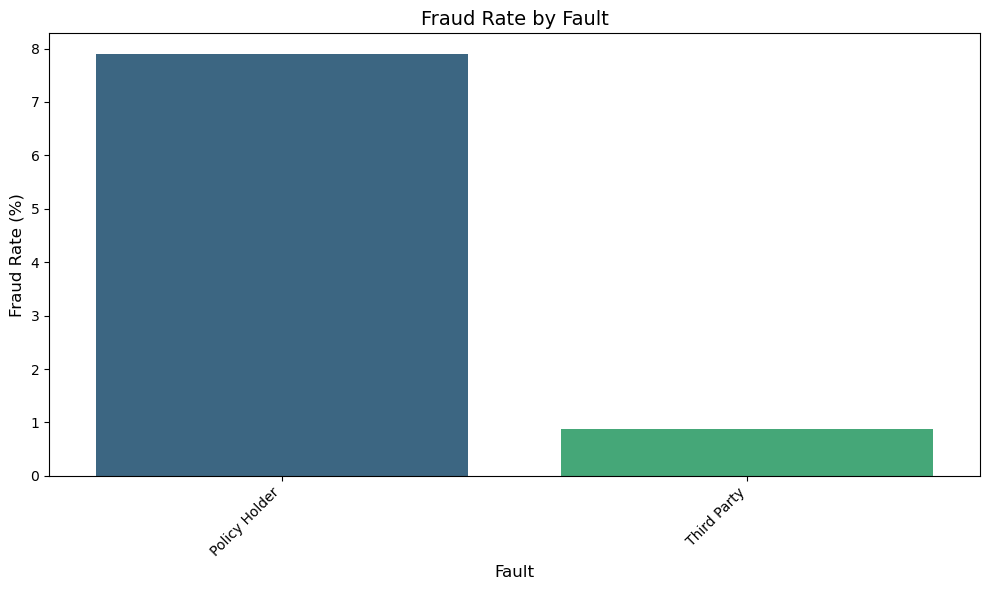


--- Fraud Rate by AgeOfPolicyHolder ---
| AgeOfPolicyHolder   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:--------------------|---------------:|---------------:|------------:|
| 21 to 25            |             16 |            108 |    14.8148  |
| 18 to 20            |              2 |             15 |    13.3333  |
| 16 to 17            |             31 |            320 |     9.6875  |
| 31 to 35            |            360 |           5593 |     6.43662 |
| over 65             |             30 |            508 |     5.90551 |
| 36 to 40            |            237 |           4043 |     5.86198 |
| 26 to 30            |             33 |            613 |     5.38336 |


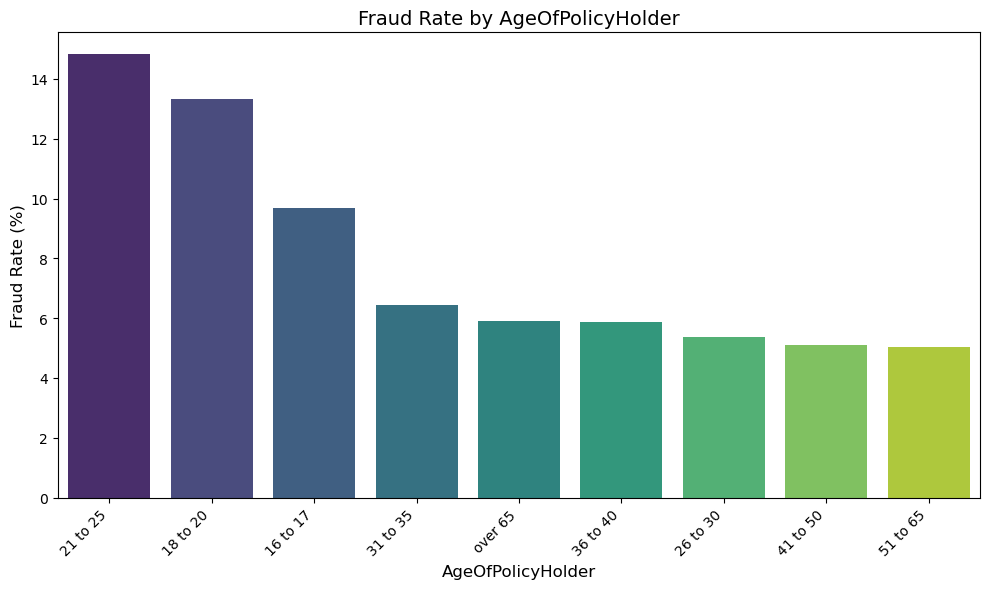


--- Fraud Rate by VehicleCategory ---
| VehicleCategory   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:------------------|---------------:|---------------:|------------:|
| Utility           |             44 |            391 |    11.2532  |
| Sedan             |            795 |           9671 |     8.22045 |
| Sport             |             84 |           5358 |     1.56775 |


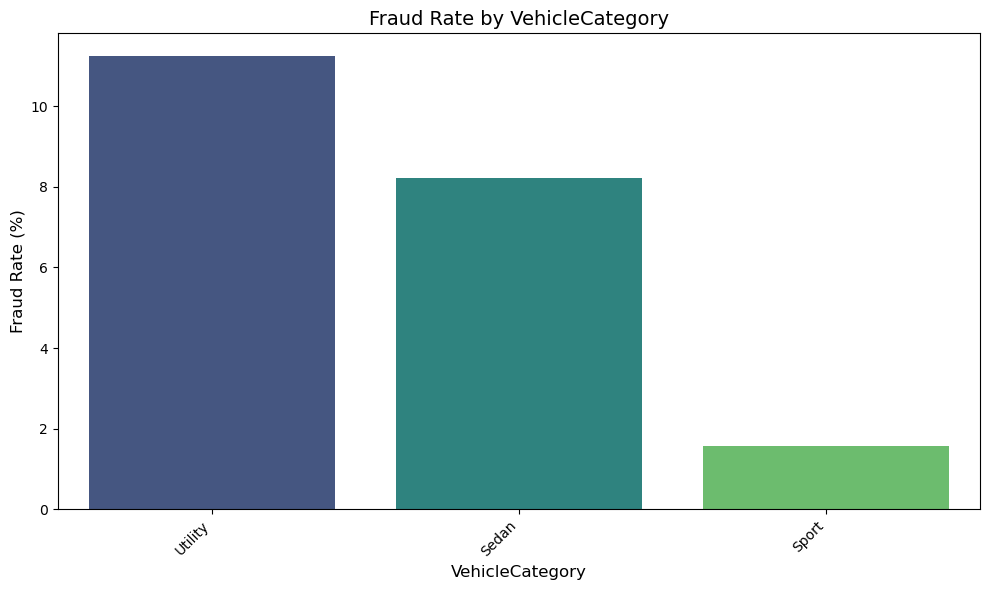


--- Fraud Rate by AccidentArea ---
| AccidentArea   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:---------------|---------------:|---------------:|------------:|
| Rural          |            133 |           1598 |     8.3229  |
| Urban          |            790 |          13822 |     5.71553 |


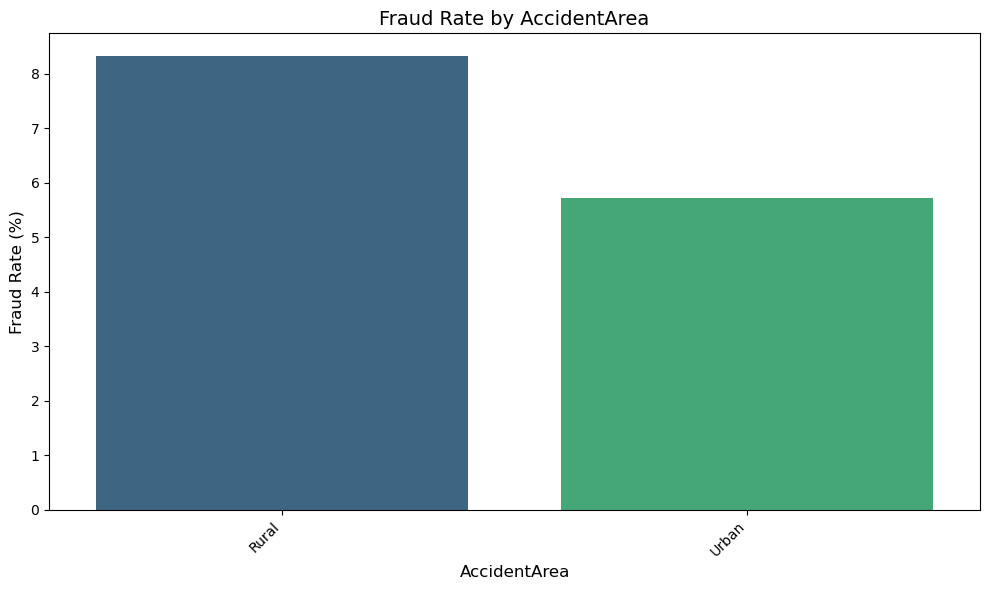


--- Fraud Rate by Days:Policy-Accident ---
| Days:Policy-Accident   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:-----------------------|---------------:|---------------:|------------:|
| none                   |              9 |             55 |    16.3636  |
| 8 to 15                |              5 |             55 |     9.09091 |
| 1 to 7                 |              1 |             14 |     7.14286 |
| 15 to 30               |              3 |             49 |     6.12245 |
| more than 30           |            905 |          15247 |     5.93559 |


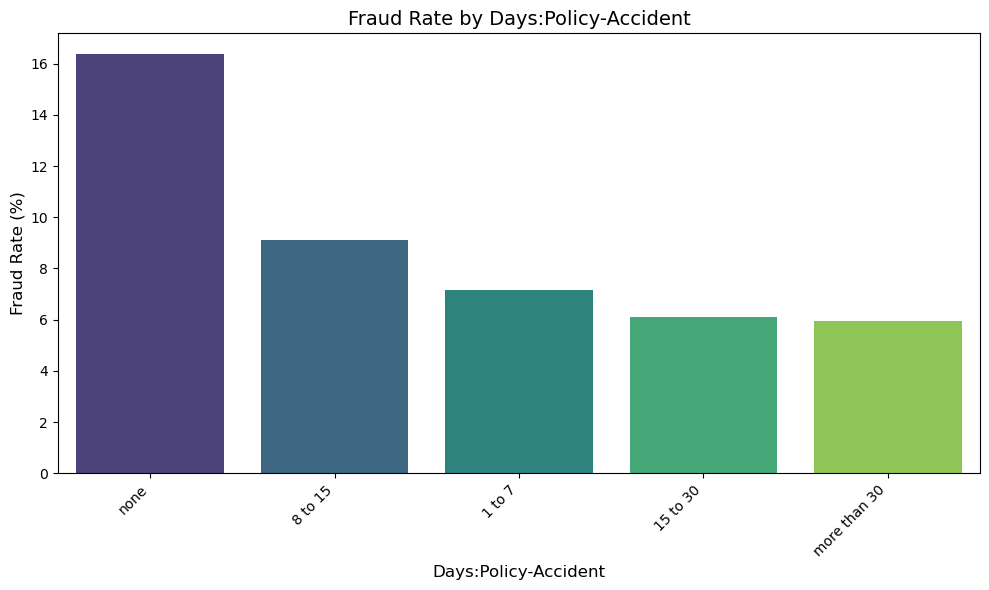


--- Fraud Rate by DayOfWeek ---
| DayOfWeek   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:------------|---------------:|---------------:|------------:|
| Sunday      |            122 |           1745 |     6.9914  |
| Saturday    |            132 |           1982 |     6.65994 |
| Friday      |            154 |           2445 |     6.29857 |
| Monday      |            160 |           2616 |     6.11621 |
| Thursday    |            120 |           2173 |     5.52232 |
| Wednesday   |            115 |           2159 |     5.32654 |
| Tuesday     |            120 |           2300 |     5.21739 |


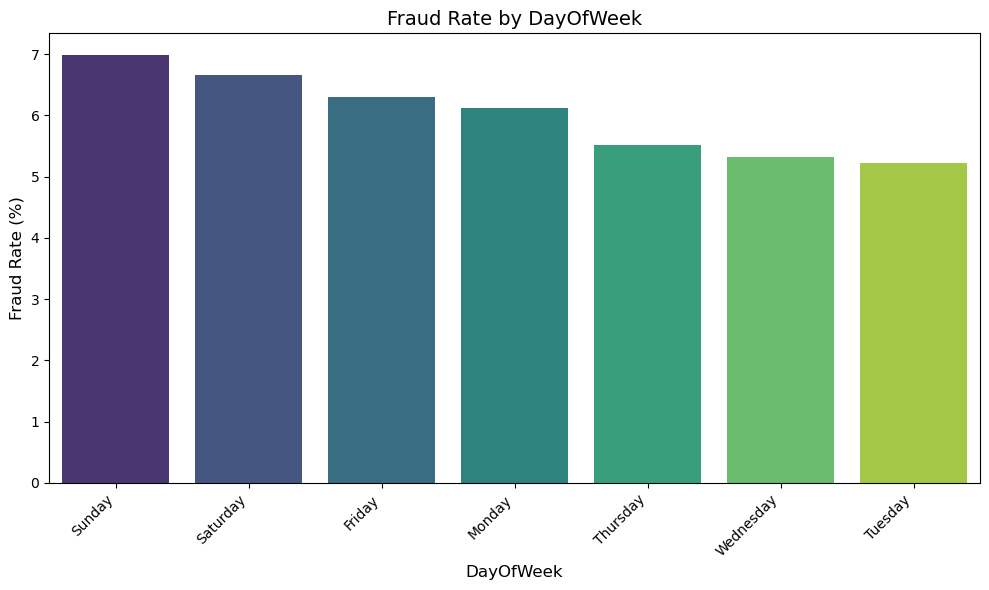


--- Fraud Rate by DayOfWeekClaimed ---
| DayOfWeekClaimed   |   Fraud_Claims |   Total_Claims |   FraudRate |
|:-------------------|---------------:|---------------:|------------:|
| Saturday           |             10 |            127 |     7.87402 |
| Friday             |            164 |           2497 |     6.56788 |
| Wednesday          |            188 |           2951 |     6.37072 |
| Tuesday            |            198 |           3375 |     5.86667 |
| Sunday             |              3 |             52 |     5.76923 |
| Monday             |            216 |           3757 |     5.74927 |
| Thursday           |            144 |           2660 |     5.41353 |


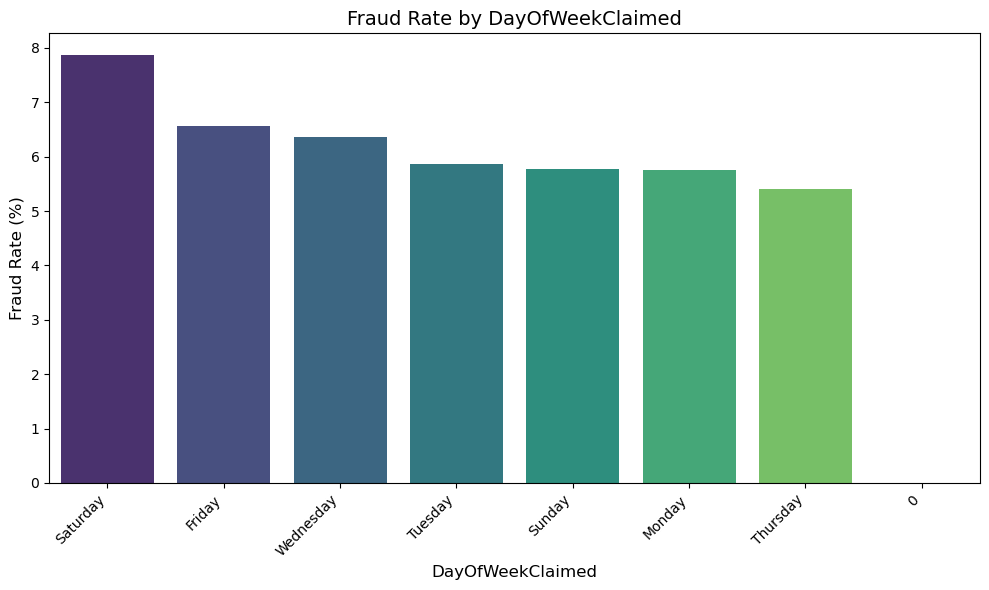

In [3]:
# Cell 3: RQ1 - High-Risk Segments Analysis (Revised to include DayOfWeek and DayOfWeekClaimed)

def calculate_and_plot_fraud_rate(data, column, title):
    # Strip whitespace from values before grouping
    data[column] = data[column].astype(str).str.strip()
    
    # Calculate fraud rate: Fraud_Claims / Total_Claims
    fraud_data = data.groupby(column)['FraudFound'].agg(['count', 'sum'])
    fraud_data.columns = ['Total_Claims', 'Fraud_Claims']
    fraud_data['FraudRate'] = (fraud_data['Fraud_Claims'] / fraud_data['Total_Claims']) * 100
    
    # Sort by FraudRate descending
    fraud_data = fraud_data.sort_values(by='FraudRate', ascending=False)
    
    print(f"\n--- Fraud Rate by {title} ---")
    print(fraud_data[['Fraud_Claims', 'Total_Claims', 'FraudRate']].head(7).to_markdown()) # Adjusted to show 7 days
    
    # Plotting
    plt.figure(figsize=(10, 6))
    sns.barplot(x=fraud_data.index, y=fraud_data['FraudRate'], palette='viridis')
    plt.title(f'Fraud Rate by {title}', fontsize=14)
    plt.xlabel(title, fontsize=12)
    plt.ylabel('Fraud Rate (%)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
# Features for analysis (Policyholder, Vehicle, Fault, Temporal)
# ADDED 'DayOfWeek' and 'DayOfWeekClaimed' to the analysis list
key_segments = [
    'Fault', 
    'AgeOfPolicyHolder', 
    'VehicleCategory', 
    'AccidentArea', 
    'Days:Policy-Accident',
    'DayOfWeek',             # Day the accident occurred
    'DayOfWeekClaimed'       # Day the claim was filed
]

# Run analysis for all key segments
for col in key_segments:
    calculate_and_plot_fraud_rate(df, col, col.replace('_', ' '))

In [6]:
# Cell 4: RQ2 - Feature Engineering and Data Split

print("\n--- 3.1 Feature Engineering ---")

# Selected categorical and numerical features for the model
cat_features = [
    'Fault', 'AccidentArea', 'VehicleCategory', 'AgeOfPolicyHolder', 
    'Days:Policy-Accident', 'PoliceReportFiled', 'WitnessPresent', 'AgentType'
]
num_features = ['Age', 'Deductible', 'DriverRating']

# Ensure all categorical columns have clean values before encoding
for col in cat_features:
    df[col] = df[col].astype(str).str.strip()

# Apply One-Hot Encoding (OHE) for selected categorical features
# drop_first=True avoids multicollinearity, which is important for Logistic Regression
df_model = pd.get_dummies(df[cat_features], drop_first=True)
df_model = pd.concat([df_model, df[num_features], df['FraudFound']], axis=1)

# Prepare feature matrix (X) and target vector (y)
X = df_model.drop('FraudFound', axis=1)
y = df_model['FraudFound']

# Split the data into Training (70%) and Test (30%) sets
# stratify=y ensures the 94:6 fraud ratio is maintained in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Model Training features: {X_train.shape[1]}")
print(f"Test Set Size: {len(X_test)}")


--- 3.1 Feature Engineering ---
Model Training features: 22
Test Set Size: 4626


In [7]:
# Cell 5: RQ2 - Model Training and Evaluation

print("\n--- 3.2 Model Training (Logistic Regression) ---")
# Use class_weight='balanced' to weigh fraud cases more heavily (crucial for imbalanced data)
log_reg = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)

# Predict probabilities (Fraud Risk Score) and classes
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]
y_pred = log_reg.predict(X_test)

# Key Metrics
auc_score = roc_auc_score(y_test, y_pred_proba)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\n--- Model Performance (Test Set) ---")
print(f"AUC Score (Risk Scoring Capability): {auc_score:.4f}")
print(f"Recall (Fraud Detection Rate): {recall:.4f} (High detection, good for minimizing losses)")
print(f"Precision (Accuracy of 'Yes' predictions): {precision:.4f} (Low precision indicates high False Positives)")

print("\nConfusion Matrix (Actual vs. Predicted):")
print(f"True Negatives (Genuine Correctly Identified): {cm[0, 0]}")
print(f"False Positives (Genuine Incorrectly Flagged): {cm[0, 1]} <-- High investigation cost")
print(f"False Negatives (Fraud Missed): {cm[1, 0]} <-- Low undetected loss")
print(f"True Positives (Fraud Correctly Identified): {cm[1, 1]}")


--- 3.2 Model Training (Logistic Regression) ---

--- Model Performance (Test Set) ---
AUC Score (Risk Scoring Capability): 0.7440
Recall (Fraud Detection Rate): 0.8809 (High detection, good for minimizing losses)
Precision (Accuracy of 'Yes' predictions): 0.1194 (Low precision indicates high False Positives)

Confusion Matrix (Actual vs. Predicted):
True Negatives (Genuine Correctly Identified): 2549
False Positives (Genuine Incorrectly Flagged): 1800 <-- High investigation cost
False Negatives (Fraud Missed): 33 <-- Low undetected loss
True Positives (Fraud Correctly Identified): 244


In [8]:
# Cell 6: RQ2 - Predictive Factors and Deliverable Export

## Identifying Predictive Factors (Coefficients)
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (Log-Odds)': log_reg.coef_[0]
})

# Sort by absolute coefficient value to see strongest predictors
coefficients['Abs_Coefficient'] = coefficients['Coefficient (Log-Odds)'].abs()
coefficients = coefficients.sort_values(by='Abs_Coefficient', ascending=False).drop('Abs_Coefficient', axis=1)

print("\n--- Top 10 Predictive Factors (Coefficients) ---")
print("Positive coefficients increase fraud risk; negative coefficients decrease risk.")
print(coefficients.head(10).to_markdown(index=False))

## Export Risk Scores (RQ2 Deliverable)
risk_scores_df = pd.DataFrame({
    'PolicyNumber': df.loc[X_test.index, 'PolicyNumber'],
    'FraudRiskScore': y_pred_proba
})
risk_scores_df.to_csv('fraud_risk_scores.csv', index=False)
print("\nSaved predicted Fraud Risk Scores to 'fraud_risk_scores.csv'")


--- Top 10 Predictive Factors (Coefficients) ---
Positive coefficients increase fraud risk; negative coefficients decrease risk.
| Feature                           |   Coefficient (Log-Odds) |
|:----------------------------------|-------------------------:|
| Fault_Third Party                 |                -2.5515   |
| VehicleCategory_Sport             |                -1.9887   |
| AgentType_Internal                |                -1.94242  |
| AgeOfPolicyHolder_18 to 20        |                 1.53333  |
| AgeOfPolicyHolder_21 to 25        |                 0.976779 |
| Days:Policy-Accident_more than 30 |                -0.641367 |
| AgeOfPolicyHolder_41 to 50        |                -0.526634 |
| AgeOfPolicyHolder_51 to 65        |                -0.446476 |
| Days:Policy-Accident_15 to 30     |                -0.431359 |
| AgeOfPolicyHolder_31 to 35        |                -0.388777 |

Saved predicted Fraud Risk Scores to 'fraud_risk_scores.csv'
